In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
df = pd.read_csv("train.csv")

N = len(df)
n = int(N * 0.2)

mean = df["Fare"].mean()

print("Population:", N)
print("Sample:", n)
print("Mean:", mean)

Population: 891
Sample: 178
Mean: 32.204207968574636


In [10]:
srs = df.sample(n=n, random_state=42)

print(srs.head())

     PassengerId  Survived  Pclass  \
709          710         1       3   
439          440         0       2   
840          841         0       3   
720          721         1       2   
39            40         1       3   

                                                  Name     Sex   Age  SibSp  \
709  Moubarek, Master. Halim Gonios ("William George")    male   NaN      1   
439             Kvillner, Mr. Johan Henrik Johannesson    male  31.0      0   
840                        Alhomaki, Mr. Ilmari Rudolf    male  20.0      0   
720                  Harper, Miss. Annie Jessie "Nina"  female   6.0      0   
39                         Nicola-Yarred, Miss. Jamila  female  14.0      1   

     Parch            Ticket     Fare Cabin Embarked  
709      1              2661  15.2458   NaN        C  
439      0        C.A. 18723  10.5000   NaN        S  
840      0  SOTON/O2 3101287   7.9250   NaN        S  
720      1            248727  33.0000   NaN        S  
39       0           

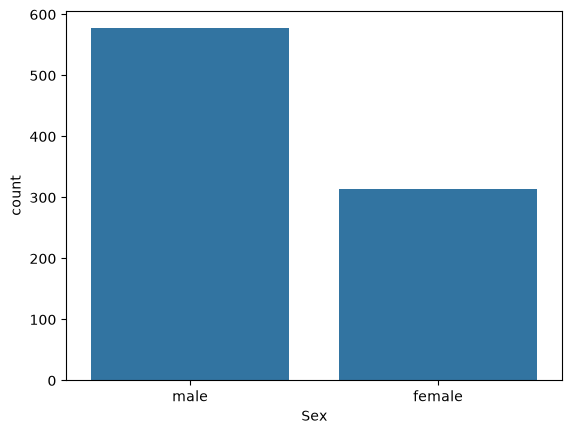

     PassengerId  Survived  Pclass  \
356          357         1       1   
79            80         1       3   
596          597         1       2   
161          162         1       2   
716          717         1       1   

                                                  Name     Sex   Age  SibSp  \
356                        Bowerman, Miss. Elsie Edith  female  22.0      0   
79                            Dowdell, Miss. Elizabeth  female  30.0      0   
596                         Leitch, Miss. Jessie Wills  female   NaN      0   
161  Watt, Mrs. James (Elizabeth "Bessie" Inglis Mi...  female  40.0      0   
716                      Endres, Miss. Caroline Louise  female  38.0      0   

     Parch      Ticket     Fare Cabin Embarked  
356      1      113505   55.000   E33        S  
79       0      364516   12.475   NaN        S  
596      0      248727   33.000   NaN        S  
161      0  C.A. 33595   15.750   NaN        S  
716      0    PC 17757  227.525   C45        C  


In [11]:
sns.countplot(data=df, x="Sex")
plt.show()

strat = df.groupby("Sex", group_keys=False).sample(
    frac=0.2, random_state=42
)

print(strat.head())

In [12]:
clusters = df["Embarked"].dropna().unique()

selected = np.random.choice(clusters, size=1, replace=False)

cluster = df[df["Embarked"].isin(selected)]

print("Selected cluster:", selected)
print(cluster.head())

Selected cluster: ['Q']
    PassengerId  Survived  Pclass                           Name     Sex  \
5             6         0       3               Moran, Mr. James    male   
16           17         0       3           Rice, Master. Eugene    male   
22           23         1       3    McGowan, Miss. Anna "Annie"  female   
28           29         1       3  O'Dwyer, Miss. Ellen "Nellie"  female   
32           33         1       3       Glynn, Miss. Mary Agatha  female   

     Age  SibSp  Parch  Ticket     Fare Cabin Embarked  
5    NaN      0      0  330877   8.4583   NaN        Q  
16   2.0      4      1  382652  29.1250   NaN        Q  
22  15.0      0      0  330923   8.0292   NaN        Q  
28   NaN      0      0  330959   7.8792   NaN        Q  
32   NaN      0      0  335677   7.7500   NaN        Q  


In [13]:
print("Population Mean:", mean)
print("SRS Mean:", srs["Fare"].mean())
print("Stratified Mean:", strat["Fare"].mean())
print("Cluster Mean:", cluster["Fare"].mean())

Population Mean: 32.204207968574636
SRS Mean: 30.76303764044944
Stratified Mean: 30.95451516853932
Cluster Mean: 13.276029870129872


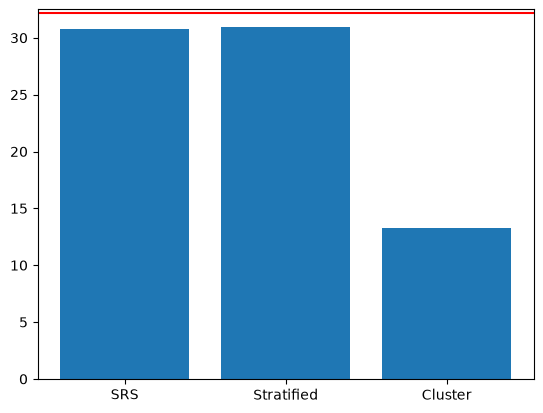

In [14]:
means = [
    srs["Fare"].mean(),
    strat["Fare"].mean(),
    cluster["Fare"].mean()
]

plt.bar(["SRS", "Stratified", "Cluster"], means)
plt.axhline(mean, color="red")
plt.show()


In [15]:
srs.to_csv("SRS.csv", index=False)
strat.to_csv("Stratified.csv", index=False)
cluster.to_csv("Cluster.csv", index=False)

print("Files saved successfully!")

Files saved successfully!
